# 6. Vector Field Visualisations
## Blue/Green Gecko
### Mia-Katrin Kvalsund
### April 2026


Code to support ALIFE 2026 paper:
 > Stovold, Kvalsund, Ludwig, Sharma, Mordvintsev "Visualising the Attractor Landscape of Neural Cellular Automata"

Based on the Colab notebook developed by Mordvintsev et al. for the ["Growing Neural Cellular Automata"](http://distill.pub/2020/growing-ca) article. and J. Stovold's notebook for the ["Neural Cellular Automata can Respond to Signals"](https://github.com/jstovold/ALIFE2023/blob/master/ExternalSignals.ipynb) article at ALIFE 2023.

Code and materials are restricted for any and all use prior to publication; post-publication the code and associated materials are available under the Apache 2.0 license


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D

from IPython.display import clear_output
import tqdm
import matplotlib.pyplot as plt

# Dimensionality reduction
from sklearn.decomposition import PCA

clear_output()

# Define and load the network

In [2]:
# no "genome" for external signals:
PARAM_N  = 0                        # Number of genes in the genome
OTHER_N  = 12                       # Number of "empty" spaces in the genome for the CA to communicate between cells
ENV_N    = 1                        # Number of environment channels (not editable by cells)

# Total number of CA state channels (+ 4 for RGBA):
CHANNEL_N = 4 + PARAM_N + OTHER_N + ENV_N

TARGET_PADDING = 2 #15                 # Number of pixels used to pad the target image border
TARGET_SIZE = 30
TARGET_PADDED_SIZE = TARGET_SIZE + TARGET_PADDING * 2

BATCH_SIZE = 12
POOL_SIZE = 1024
CELL_FIRE_RATE = 0.5

EXPERIMENT_TYPE = "Regenerating" #param ["Growing", "Persistent", "Regenerating"]
EXPERIMENT_MAP = {"Growing":0, "Persistent":1, "Regenerating":2}
EXPERIMENT_N = EXPERIMENT_MAP[EXPERIMENT_TYPE]

USE_PATTERN_POOL = [0, 1, 1][EXPERIMENT_N]
DAMAGE_N = [0, 0, 3][EXPERIMENT_N]  # Number of patterns to damage in a batch

BEHAVIOUR_SWITCH=2001               # at what point do we change the way we present the target images to the network?

fix_seed = True                     # for reproducibility
loading_from_file = True
saving = False
add_noise = True

In [3]:
def to_rgba(x):
  return x[..., :4]

def to_alpha(x):
  return tf.clip_by_value(x[..., 3:4], 0.0, 1.0)

def to_rgb(x):
  # assume rgb premultiplied by alpha
  rgb, a = x[..., :3], to_alpha(x)
  return 1.0-a+rgb


def get_channels(x, ch=[5,6,7]):
  rgb, a = x[..., ch], to_alpha(x)
  return 1.0-a+rgb

def get_living_mask(x, threshold = 0.1):
  alpha = x[:, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > threshold

def get_living(x):
  alpha = x[0, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > 0.1


def make_seed(size, n=1):
  x = np.zeros([n, size, size, CHANNEL_N], np.float32)
  x[:, size//2, size//2, 3:] = 1.0
  return x



@tf.function
def get_stim(jitter=False):
  size = TARGET_PADDED_SIZE
  stim_x = (size // 2) - (TARGET_SIZE // 10)
  stim_y = (size // 2) - (TARGET_SIZE // 10)

  if jitter:
    rand = tf.random.uniform(shape=(), minval=-1, maxval=1, dtype=tf.int32)
    stim_x = stim_x + rand
    stim_y = stim_y + rand

  return (stim_x, stim_y)

class CAModel(tf.keras.Model):

  def __init__(self, channel_n=CHANNEL_N, fire_rate=CELL_FIRE_RATE):
    super().__init__()
    self.channel_n = channel_n
    self.fire_rate = fire_rate

    self.dmodel = tf.keras.Sequential([
          Conv2D(128, 1, activation=tf.nn.relu, name='layer1'),
          Conv2D(self.channel_n - ENV_N, 1, activation=None,             # no update for ENV_N state
              kernel_initializer=tf.zeros_initializer, name='layer2'),
    ])

    self(tf.zeros([1, 3, 3, channel_n]))  # dummy call to build the model

  # OBS: This function has been changed because package version between colab and my Mac M1 are different. Function has been verified. 
  def perceive(self, x, angle=0.0):
    batch, height, width, in_channels = x.shape

    # Identity kernel
    identify = tf.constant([[0.,0.,0.],
                            [0.,1.,0.],
                            [0.,0.,0.]], dtype=tf.float32)
    # Sobel kernels
    dx = tf.constant([[1,2,1],
                      [0,0,0],
                      [-1,-2,-1]], dtype=tf.float32) / 8.0
    dy = tf.transpose(dx)

    # Rotate kernels 180° (flip both axes)
    identify = tf.reverse(identify, axis=[0,1])
    dx = tf.reverse(dx, axis=[0,1])
    dy = tf.reverse(dy, axis=[0,1])

    # Expand kernels to depthwise shape
    # shape: [3,3,1,1] → will be broadcasted to all input channels
    id_k = identify[:, :, None, None]
    dx_k = dy[:, :, None, None]  # swapped like in your working code
    dy_k = dx[:, :, None, None]

    # Repeat kernels across all input channels (channel_multiplier=1)
    id_k = tf.repeat(id_k, in_channels, axis=2)
    dx_k = tf.repeat(dx_k, in_channels, axis=2)
    dy_k = tf.repeat(dy_k, in_channels, axis=2)

    # Apply depthwise convolution
    y_id = tf.nn.depthwise_conv2d(x, id_k, [1,1,1,1], 'SAME')
    y_dx = tf.nn.depthwise_conv2d(x, dx_k, [1,1,1,1], 'SAME')
    y_dy = tf.nn.depthwise_conv2d(x, dy_k, [1,1,1,1], 'SAME')

    # Reshape and interleave channels: from [H,W,in_channels] → [H,W,in_channels*3]
    # Stack along last axis per channel
    y = tf.reshape(tf.stack([y_id, y_dx, y_dy], axis=-1), [batch, height, width, in_channels*3])

    return y

  @tf.function
  def call(self, x, fire_rate=None, angle=0.0, step_size=1.0, fire_mask=None, return_fire_mask=False):
    pre_life_mask = get_living_mask(x)
    y = self.perceive(x, angle)


    z = self.dmodel(y)
    dx = z*step_size


    if fire_rate is None:
      fire_rate = self.fire_rate

    if fire_mask is None:
      fire_mask = tf.random.uniform(tf.shape(x[:, :, :, :1]))

    update_mask = fire_mask <= fire_rate
    x = x[...,:-ENV_N] + dx * tf.cast(update_mask, tf.float32)
    x = tf.pad(x, tf.constant([[0,0],[0,0],[0,0], [0,ENV_N]]), constant_values=0) # add the environment vars back into the state vector (set to 0)

    post_life_mask = get_living_mask(x)
    life_mask = pre_life_mask & post_life_mask

    if return_fire_mask:
      return x * tf.cast(life_mask, tf.float32), fire_mask
    else:
      return x * tf.cast(life_mask, tf.float32)

ca = CAModel()
ca.load_weights("model/blue_green_salamander/big10000.weights.h5")

2026-03-23 18:28:56.615501: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-03-23 18:28:56.615529: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-03-23 18:28:56.615535: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-03-23 18:28:56.615553: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-03-23 18:28:56.615566: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-03-23 18:28:57.089824: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


### Make the seed

In [4]:
h, w = [TARGET_PADDING*2 + TARGET_SIZE] * 2
print(h,w)
seed = np.zeros([h, w, CHANNEL_N], np.float32)
seed[h//2, w//2, 3:]  = 1.0

34 34


In [5]:
x = seed[None, ...]
x = tf.convert_to_tensor(x, dtype=tf.float32)
x.shape

TensorShape([1, 34, 34, 17])

### Run the system for some time

In [6]:
#@title Generate data for Autoencoder

TIMESTEPS = 5000

# record of all NCA states
states = [tf.identity(x)]

for i in tqdm.trange(TIMESTEPS):
  x = ca(x)
  states.append(tf.identity(x))

  if i > 0 and i % 150 == 0:
    stim_x,stim_y = get_stim(jitter=True)
    x = x.numpy()
    x[:,stim_y, stim_x,-ENV_N:] = 1.0
    x = tf.convert_to_tensor(x, dtype=tf.float32)

  if i > 0 and i % 1500 == 0:
    x = seed[None, ...]
    x = tf.convert_to_tensor(x, dtype=tf.float32)

100%|██████████| 5000/5000 [00:15<00:00, 313.43it/s]


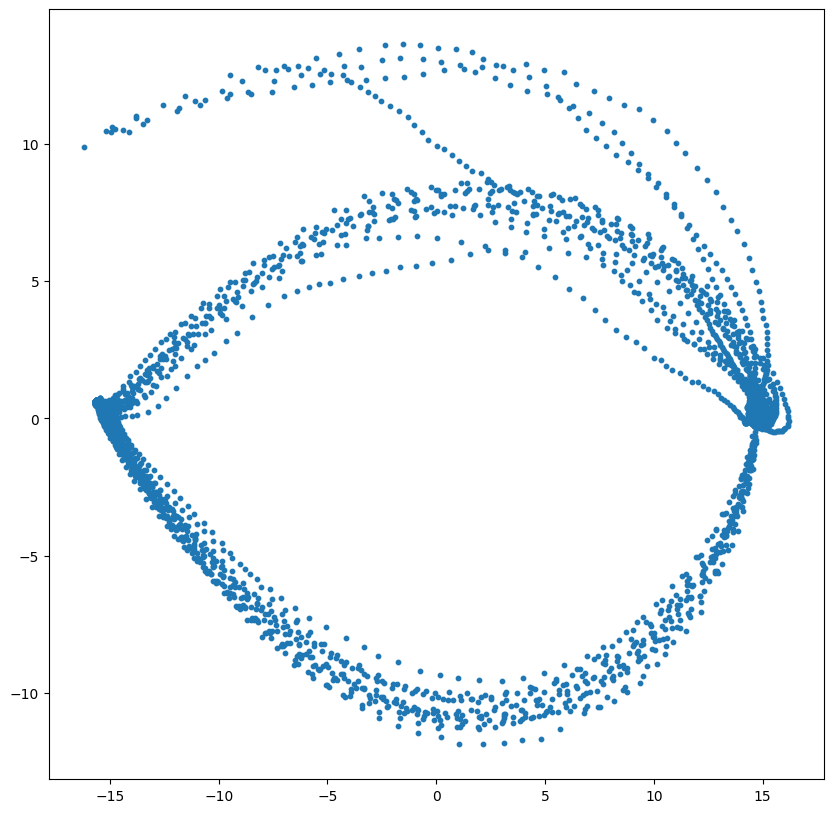

In [7]:
states_np = tf.stack(states).numpy()

T, B, H, W, C = states_np.shape
flattened_states = states_np.reshape(T*B, H*W*C) # [100:] # Discard the first 100 timesteps, seed to green salamander

X2 = PCA(n_components=2).fit_transform(flattened_states)
plt.figure(figsize=(10,10))
plt.scatter(X2[:,0], X2[:,1], s=10)
plt.show()

# Moving onto vector fields

First, I want to see if the inverse PCA is good enough to use to create the vector field

In [8]:
n_components = 2
pca = PCA(n_components=n_components)
pca.fit(flattened_states)
reduced_states = pca.transform(flattened_states)
print(reduced_states.shape)

max_x, max_y = reduced_states[:, :2].max(axis=0)
min_x, min_y = reduced_states[:, :2].min(axis=0)

(5001, 2)


### How good is PCA at recreating states by inverse transform?

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4163186..1.120795].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.021632727..1.0180537].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.047941476..1.0146449].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.2865789796939353..1.4036467490653664].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.23092318856763505..1.2034677684050816].


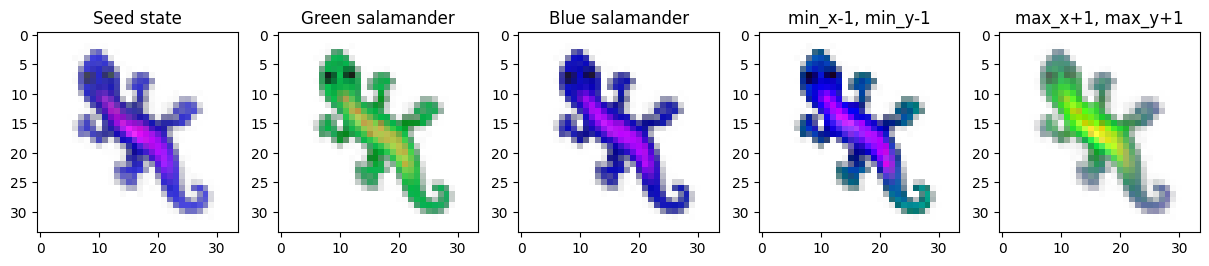

In [9]:
inverse_reduced_states = pca.inverse_transform(reduced_states)

green_t = 149 # This is the timestep right before the signal to change color is sent
blue_t = 299 # This is the timestep right before the signal to change color is sent

plt.figure(figsize=(15,5))
plt.subplot(1,5,1)
plt.title("Seed state")
plt.imshow(inverse_reduced_states[0].reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,2)
plt.title("Green salamander")
plt.imshow(inverse_reduced_states[green_t].reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,3)
plt.title("Blue salamander")
plt.imshow(inverse_reduced_states[blue_t].reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,4)
plt.title("min_x-1, min_y-1")
inverse_random_state = pca.inverse_transform(np.array([[min_x-1, min_y-1]+[0]*(n_components-2)]))
plt.imshow(inverse_random_state.reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,5)
plt.title("max_x+1, max_y+1")
inverse_random_state = pca.inverse_transform(np.array([[max_x+1, max_y+1]+[0]*(n_components-2)]))
plt.imshow(inverse_random_state.reshape(H, W, C)[:,:,:4])

As seen from the max and min salamanders, we need a more sophisticated way of calculating the PCA vector beyond the x and y coordinate. I suggest an interpolation technique: 

xy[j] = sum over i ( closeness(xy[j,:D], pca[i,:D]) * data[i] )

where closeness(a,b) must be some function that is close to 1 for closest and close to 0 for furthest

# Using an interpolation technique instead

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.07087469..1.0844266].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.048059557..1.1142832].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.056007244..1.0844266].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.050924778..1.0844266].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.050924778..1.0844266].


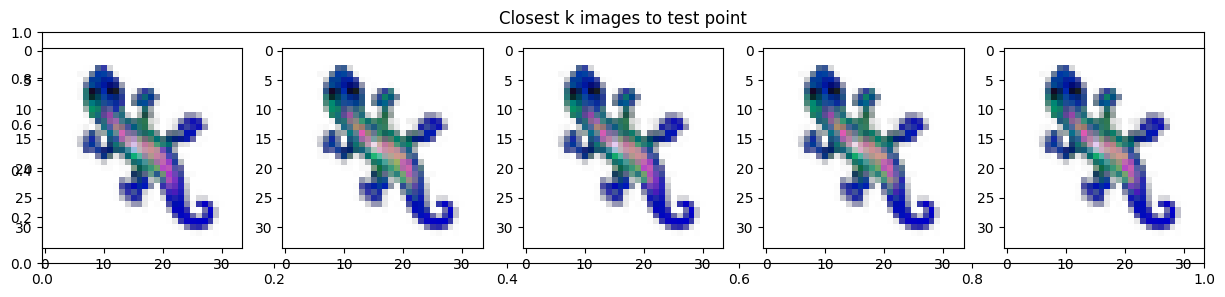

In [10]:
test_point = np.array([[0, 0]])

def closeness_vector(reduced_states, test_point, k=5):
    def closeness(a, b):
        # 0 is close, + values are further
        return  np.linalg.norm(a[:2] - b[:2])
    
    def softmax(x):
        return np.exp(x) / np.sum(np.exp(x))

    closenesses = []

    for i in range(len(reduced_states)):
        closenesses.append(closeness(reduced_states[i], test_point))
    
    # Only the closest k will be used, rest is 0
    closeness_vec = np.zeros(len(reduced_states))

    k_closest_distances = np.sort(closenesses)[:k]
    k_closest_indexes = np.argsort(closenesses)[:k]
    
    # Now closest is almost 1 and smaller is further away
    inverted = 1 - k_closest_distances

    # softmax takes care of normalizing
    closeness_vec[k_closest_indexes] = softmax(inverted)
    return closeness_vec

closest_images = states_np[np.argsort(closeness_vector(reduced_states, test_point[0]))[-5:]]

plt.figure(figsize=(15,3))
plt.title("Closest k images to test point")
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(closest_images[i].reshape(H, W, C)[:,:,:4])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.046482076863023754..1.0773253853067473].


(1, 34, 34, 17)


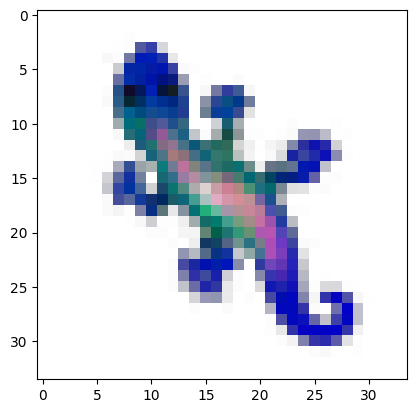

In [11]:
def calculate_point(test_point, reduced_states, states_np, k=100):
    norm_dist = closeness_vector(reduced_states, test_point, k=k)

    closest_images = states_np[np.argsort(norm_dist)[-k:]]

    dists = norm_dist[np.argsort(norm_dist)[-k:]]
    dists = dists[:,None, None, None, None] # Reshape to multiply later

    return np.sum(closest_images * dists, axis=0)

test_point = np.array([[0, 0]+[0]*(n_components-2)])
inverse_test_point = calculate_point(test_point[0], reduced_states, states_np)
print(inverse_test_point.shape)


plt.imshow(inverse_test_point.reshape(H, W, C)[:,:,:4])

### Now, let's test our new method

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.1732561423432358..1.1756499126743958].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.026981656888804904..1.046389835051367].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.038519832854283585..1.0418137854545109].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.06469925986801728..1.0527501939787407].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0727592035672201..1.2006458022781492].


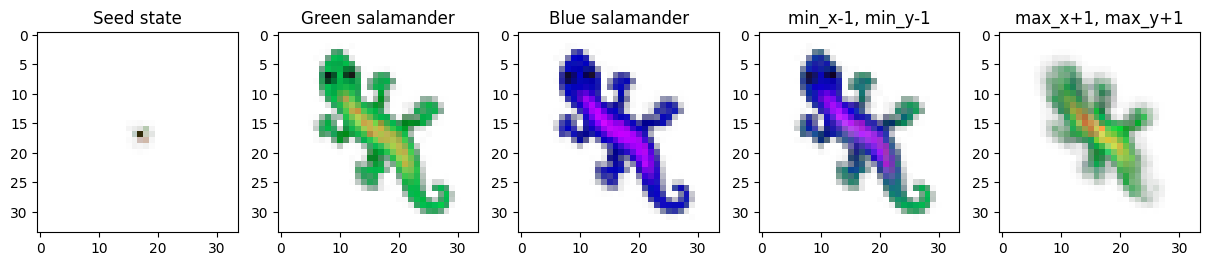

In [12]:
test_points = np.array([[-16,11], [15, 0], [-15,0], [min_x-1, min_y-1], [max_x+1, max_y+1]])
inverse_reduced_states = [calculate_point(test_points[i], reduced_states, states_np, k=20) for i in range(len(test_points))]

plt.figure(figsize=(15,5))
plt.subplot(1,5,1)
plt.title("Seed state")
plt.imshow(inverse_reduced_states[0].reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,2)
plt.title("Green salamander")
plt.imshow(inverse_reduced_states[1].reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,3)
plt.title("Blue salamander")
plt.imshow(inverse_reduced_states[2].reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,4)
plt.title("min_x-1, min_y-1")
plt.imshow(inverse_reduced_states[3].reshape(H, W, C)[:,:,:4])

plt.subplot(1,5,5)
plt.title("max_x+1, max_y+1")
plt.imshow(inverse_reduced_states[4].reshape(H, W, C)[:,:,:4])

It's much better at recreating the seed state, and the interpolated states, though blurry, seem accurate enough.

### Using the new method

In [13]:
# Create grid

x_linspace = np.linspace(min_x-1, max_x+1, 20)
y_linspace = np.linspace(min_y-1, max_y+1, 15)

xx, yy = np.meshgrid(x_linspace, y_linspace)
xy = np.stack([xx, yy], axis=-1).reshape(-1, 2)

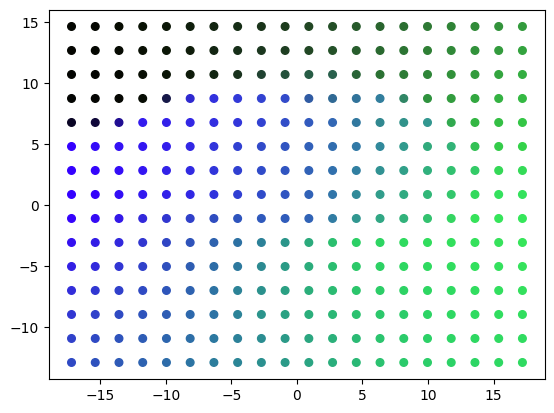

In [14]:
# Calculate points in the original basis that corresond to the grid

z = [calculate_point(test_point, reduced_states, states_np, k=20) for test_point in xy]
z = np.stack(z)
z = z.reshape(-1, H, W, C)

# Color grid by point colors
def get_point_colors(z):
    point_colors = z[..., :3]

    # Take the mean across the substrate, leaving only the average RGB color per substrate
    point_colors = np.mean(point_colors, axis=(-2, -3))

    # Normalize
    point_colors -= np.min(point_colors)
    point_colors /= (np.max(point_colors))

    return point_colors

point_colors = get_point_colors(z)

plt.scatter(xy[:, 0], xy[:, 1], s=30, c=point_colors)

In [15]:
# Run through to get the direction

for _ in range(10):
    z = ca(z)

# Calculate the direction vector in PCA space

new_xy = pca.transform(z.numpy().reshape(-1, H*W*C))

directions = new_xy[:, :2] - xy
directions /= np.linalg.norm(directions, axis=-1, keepdims=True)

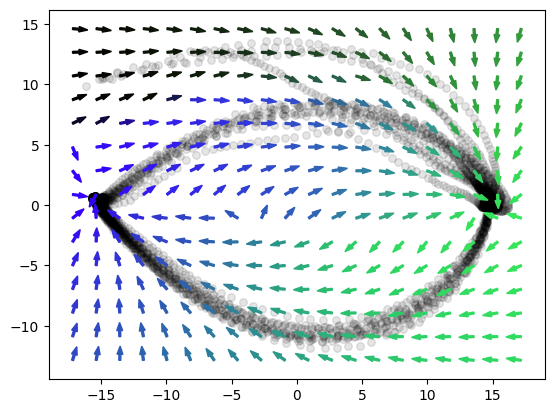

In [16]:
plt.figure()
plt.scatter(reduced_states[:, 0], reduced_states[:, 1], s=30, c='k', alpha=0.1)

# Show arrows
for (x, y), (dx, dy), color in zip(xy, directions, point_colors):
    # Division by 2 makes the arrows shorter
    plt.arrow(x, y, dx/2, dy/2, color=color, width=0.15)

### Testing for different k

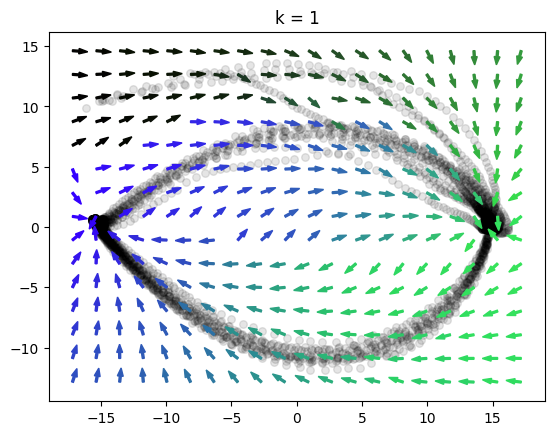

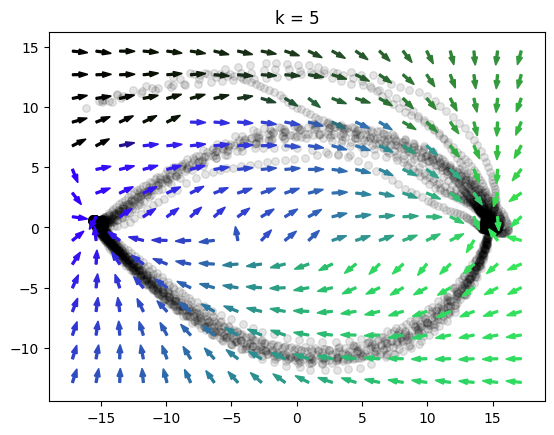

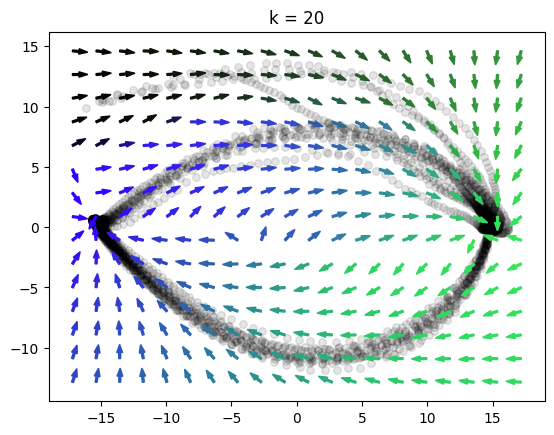

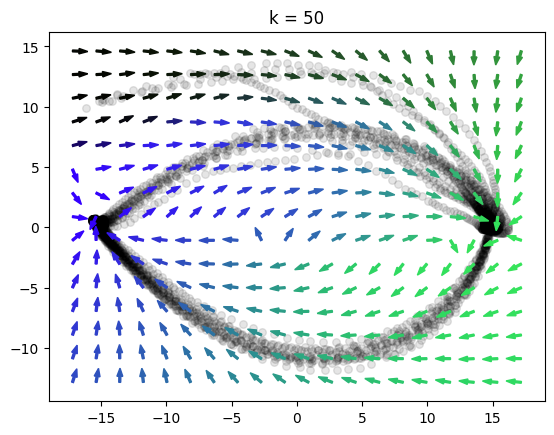

In [17]:
def plot_vector_field(k):
    # Calculate points in the original basis that corresond to the grid

    z = [calculate_point(test_point, reduced_states, states_np, k=k) for test_point in xy]
    z = np.stack(z)
    z = z.reshape(-1, H, W, C)

    # Color grid by point colors

    point_colors = get_point_colors(z)

    # Run through to get the direction

    for _ in range(10):
        z = ca(z)

    # Calculate the direction vector in PCA space

    new_xy = pca.transform(z.numpy().reshape(-1, H*W*C))

    directions = new_xy[:, :2] - xy
    directions /= np.linalg.norm(directions, axis=-1, keepdims=True)

    plt.figure()
    plt.title("k = " + str(k))
    plt.scatter(reduced_states[:, 0], reduced_states[:, 1], s=30, c='k', alpha=0.1)

    # Show arrows
    for (x, y), (dx, dy), color in zip(xy, directions, point_colors):
        # Division by 2 makes the arrows shorter
        plt.arrow(x, y, dx/2, dy/2, color=color, width=0.15)

plot_vector_field(1)
plot_vector_field(5)
plot_vector_field(20)
plot_vector_field(50)